## Import scikit-learn modules

In [37]:
from sklearn.model_selection import train_test_split
from sklearn import metrics
from sklearn import preprocessing
from sklearn.decomposition import PCA
from sklearn import tree
from sklearn.cluster import KMeans

## Data Preparation

In [38]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [39]:
#os stands for operating system package
import os

# Check current directory
print(os.getcwd())

os.chdir(r'C:/Users/Darren/Downloads/SUSS SST101,PSY107,ANL252/ANL252 Lectures/ANL252 Dataset')
fruits_extra = pd.read_csv("fruits_extra.csv")
fruits_extra

C:\Users\Darren\Downloads\SUSS SST101,PSY107,ANL252\ANL252 Lectures\ANL252 Dataset


,Fruits,Prices,Country
0,Apple,1.2,Africa
1,Orange,0.7,Russia
2,Banana,0.9,New Zealand
3,Big Apple,1.3,Africa


In [40]:
# Reducing Categories
fruits_extra["Fruits"].replace("Big Apple", "Apple")

# Alternative way 
fruits_extra["Fruits"] = fruits_extra["Fruits"].replace("Big Apple", "Apple")
fruits_extra

,Fruits,Prices,Country
0,Apple,1.2,Africa
1,Orange,0.7,Russia
2,Banana,0.9,New Zealand
3,Apple,1.3,Africa


In [41]:
# Rename variables
fruits_extra = fruits_extra.rename(columns = {'Prices': 'Prices ($)'})
fruits_extra

,Fruits,Prices ($),Country
0,Apple,1.2,Africa
1,Orange,0.7,Russia
2,Banana,0.9,New Zealand
3,Apple,1.3,Africa


In [42]:
# Dummy Variables Conversion
pd.get_dummies(fruits_extra)

,Prices ($),Fruits_Apple,Fruits_Banana,Fruits_Orange,Country_Africa,Country_New Zealand,Country_Russia
0,1.2,True,False,False,True,False,False
1,0.7,False,False,True,False,False,True
2,0.9,False,True,False,False,True,False
3,1.3,True,False,False,True,False,False


In [43]:
fruits_extra = pd.get_dummies(fruits_extra, dtype=int)
fruits_extra

# 1 for true, 0 for false

,Prices ($),Fruits_Apple,Fruits_Banana,Fruits_Orange,Country_Africa,Country_New Zealand,Country_Russia
0,1.2,1,0,0,1,0,0
1,0.7,0,0,1,0,0,1
2,0.9,0,1,0,0,1,0
3,1.3,1,0,0,1,0,0


In [44]:
# Dependent Variable Y  to be extracted from dataframe
y = fruits_extra[["Prices ($)"]]
y

,Prices ($)
0,1.2
1,0.7
2,0.9
3,1.3


In [ ]:
# Independent Variable X extract from original dataframe
x = fruits_extra.drop(["Prices ($)"], axis = 1) # axis = 1 => we drop columns
x

,Fruits_Apple,Fruits_Banana,Fruits_Orange,Country_Africa,Country_New Zealand,Country_Russia
0,1,0,0,1,0,0
1,0,0,1,0,0,1
2,0,1,0,0,1,0
3,1,0,0,1,0,0


In [46]:
x = fruits_extra[["Fruits_Apple", "Fruits_Banana", "Fruits_Orange"]]
x

,Fruits_Apple,Fruits_Banana,Fruits_Orange
0,1,0,0
1,0,0,1
2,0,1,0
3,1,0,0


## Linear Regression

In [47]:
from sklearn.linear_model import LinearRegression

In [48]:

boston = pd.read_csv("BostonHousing.csv")
boston

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98,24.0
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14,21.6
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03,34.7
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94,33.4
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33,36.2
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,9.67,22.4
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08,20.6
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64,23.9
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48,22.0


In [49]:
y = boston[["medv"]]
x = boston.drop(["medv"], axis = 1)
display(y)
display(x)

,medv
0,24.0
1,21.6
2,34.7
3,33.4
4,36.2
...,...
501,22.4
502,20.6
503,23.9
504,22.0


,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat
0,0.00632,18.0,2.31,0,0.538,6.575,65.2,4.0900,1,296,15.3,396.90,4.98
1,0.02731,0.0,7.07,0,0.469,6.421,78.9,4.9671,2,242,17.8,396.90,9.14
2,0.02729,0.0,7.07,0,0.469,7.185,61.1,4.9671,2,242,17.8,392.83,4.03
3,0.03237,0.0,2.18,0,0.458,6.998,45.8,6.0622,3,222,18.7,394.63,2.94
4,0.06905,0.0,2.18,0,0.458,7.147,54.2,6.0622,3,222,18.7,396.90,5.33
...,...,...,...,...,...,...,...,...,...,...,...,...,...
501,0.06263,0.0,11.93,0,0.573,6.593,69.1,2.4786,1,273,21.0,391.99,9.67
502,0.04527,0.0,11.93,0,0.573,6.120,76.7,2.2875,1,273,21.0,396.90,9.08
503,0.06076,0.0,11.93,0,0.573,6.976,91.0,2.1675,1,273,21.0,396.90,5.64
504,0.10959,0.0,11.93,0,0.573,6.794,89.3,2.3889,1,273,21.0,393.45,6.48


In [50]:
lr = LinearRegression()

In [51]:
lr.fit(x, y)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](1, 13)","[[-0.11, 0.05, 0.02,...,-0.95, 0.01,-0.52]]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](13,)","['crim','zn','indus',...,'ptratio','b','lstat']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.","ndarray[float64](1,)",[36.46]
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,13
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(13)


In [52]:
print("Intercept: ", lr.intercept_)
print("Coefficients: ", lr.coef_)

Intercept:  [36.45948839]
Coefficients:  [[-1.08011358e-01  4.64204584e-02  2.05586264e-02  2.68673382e+00
  -1.77666112e+01  3.80986521e+00  6.92224640e-04 -1.47556685e+00
   3.06049479e-01 -1.23345939e-02 -9.52747232e-01  9.31168327e-03
  -5.24758378e-01]]


In [53]:
[36.45948838509025,
 -0.10801135783679722,
  0.0464204583668797,
  0.02055862636707164,
  2.686733819344969,
  -17.766611228300402,
  3.809865206809207,
  0.0006922246403458607,
  -1.4755668456002493,
  0.3060494789851746,
  -0.012334593916574613,
  -0.9527472317072914,
  0.009311683273793501,
  -0.5247583778554901]

[36.45948838509025,
 -0.10801135783679722,
 0.0464204583668797,
 0.02055862636707164,
 2.686733819344969,
 -17.766611228300402,
 3.809865206809207,
 0.0006922246403458607,
 -1.4755668456002493,
 0.3060494789851746,
 -0.012334593916574613,
 -0.9527472317072914,
 0.009311683273793501,
 -0.5247583778554901]

In [54]:
est = list(lr.intercept_) + np.squeeze(lr.coef_).tolist()
est

[np.float64(36.45948838508985),
 -0.10801135783679726,
 0.04642045836688162,
 0.020558626367072175,
 2.686733819344969,
 -17.766611228300405,
 3.80986520680924,
 0.0006922246403435212,
 -1.4755668456002555,
 0.3060494789851744,
 -0.01233459391657437,
 -0.9527472317072883,
 0.009311683273793822,
 -0.5247583778554833]

In [55]:
xnames = ["intercept"] + list(x.columns.values)
xnames

['intercept',
 'crim',
 'zn',
 'indus',
 'chas',
 'nox',
 'rm',
 'age',
 'dis',
 'rad',
 'tax',
 'ptratio',
 'b',
 'lstat']

In [56]:
coef_tab = pd.DataFrame({"Parameter": xnames, "Estimates": est})
coef_tab

,Parameter,Estimates
0,intercept,36.459488
1,crim,-0.108011
2,zn,0.046420
3,indus,0.020559
4,chas,2.686734
5,nox,-17.766611
6,rm,3.809865
7,age,0.000692
8,dis,-1.475567
9,rad,0.306049


## K-Means Clustering

In [57]:
import os
## os.environ["OMP_NUM_THREADS"] = "2" # Just to avoid warning message of memory leak

In [58]:
from sklearn.cluster import KMeans

In [59]:
boston_km = KMeans(n_clusters = 4, init = "k-means++", n_init = 10, max_iter = 300, tol = 0.0001, random_state = None)
boston_km_fit = boston_km.fit(x, sample_weight = None)

In [60]:
print(boston_km_fit.labels_)
print(len(boston_km_fit.labels_))

[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 2 2 2 2 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 3 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 2 2 0 0 0 0 0 0 0 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2
 2 2 2 2 2 2 2 3 3 2 2 2 2 2 2 2 2 2 2 2 2 2 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 2 2 2 2 2 2 0 0 0 0 0 0 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0
 0 0 2 2 2 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 2 2 2 0 0
 0 0 0 0 0 0 0 0 0 2 2 2 2 2 0 0 0 0 2 2 0 0 0 1 1 1 1 1 1 1 1 1 1 1 3 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 3 3 3 3 3 3 3 3 3 3 3 1 1 1 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 3 1 1 1 1 1
 1 3 1 1 1 1 3 1 1 1 3 3 3 3 1 1 1 1 1 1 1 1 3 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 

In [61]:
colors = {0: "red", 1: "blue", 2: "green", 3: "orange"}
boston["cluster"] = boston_km_fit.labels_
boston.tail(30)

,crim,zn,indus,chas,nox,rm,age,dis,rad,tax,ptratio,b,lstat,medv,cluster
476,4.87141,0.0,18.10,0,0.614,6.484,93.6,2.3053,24,666,20.2,396.21,18.68,16.7,1
477,15.02340,0.0,18.10,0,0.614,5.304,97.3,2.1007,24,666,20.2,349.48,24.91,12.0,1
478,10.23300,0.0,18.10,0,0.614,6.185,96.7,2.1705,24,666,20.2,379.70,18.03,14.6,1
479,14.33370,0.0,18.10,0,0.614,6.229,88.0,1.9512,24,666,20.2,383.32,13.11,21.4,1
480,5.82401,0.0,18.10,0,0.532,6.242,64.7,3.4242,24,666,20.2,396.90,10.74,23.0,1
481,5.70818,0.0,18.10,0,0.532,6.750,74.9,3.3317,24,666,20.2,393.07,7.74,23.7,1
482,5.73116,0.0,18.10,0,0.532,7.061,77.0,3.4106,24,666,20.2,395.28,7.01,25.0,1
483,2.81838,0.0,18.10,0,0.532,5.762,40.3,4.0983,24,666,20.2,392.92,10.42,21.8,1
484,2.37857,0.0,18.10,0,0.583,5.871,41.9,3.7240,24,666,20.2,370.73,13.34,20.6,1
485,3.67367,0.0,18.10,0,0.583,6.312,51.9,3.9917,24,666,20.2,388.62,10.58,21.2,1


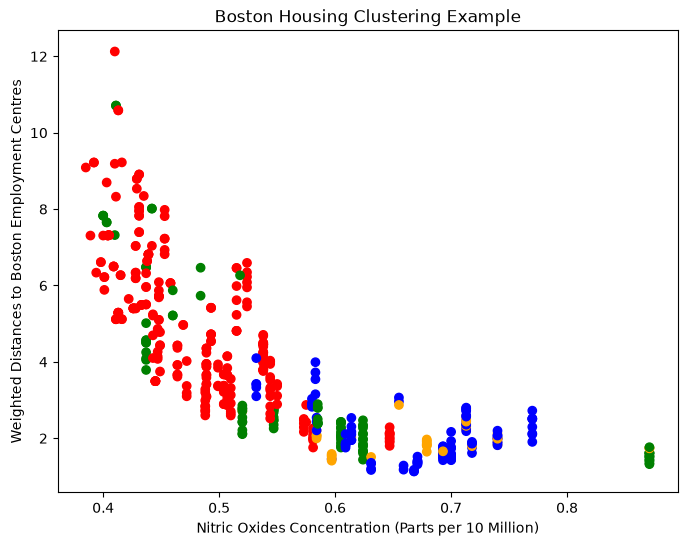

In [62]:
plt.figure(figsize = (8, 6))
plt.scatter(x = boston["nox"], y = boston["dis"], color = boston["cluster"].map(colors))
plt.xlabel("Nitric Oxides Concentration (Parts per 10 Million)")
plt.ylabel("Weighted Distances to Boston Employment Centres")
plt.title("Boston Housing Clustering Example")
plt.show()

## Decision Trees

In [63]:
from sklearn import tree

In [64]:
boston_tree = tree.DecisionTreeRegressor(max_depth = 4)
boston_tree_fit = boston_tree.fit(x, y, sample_weight = None)

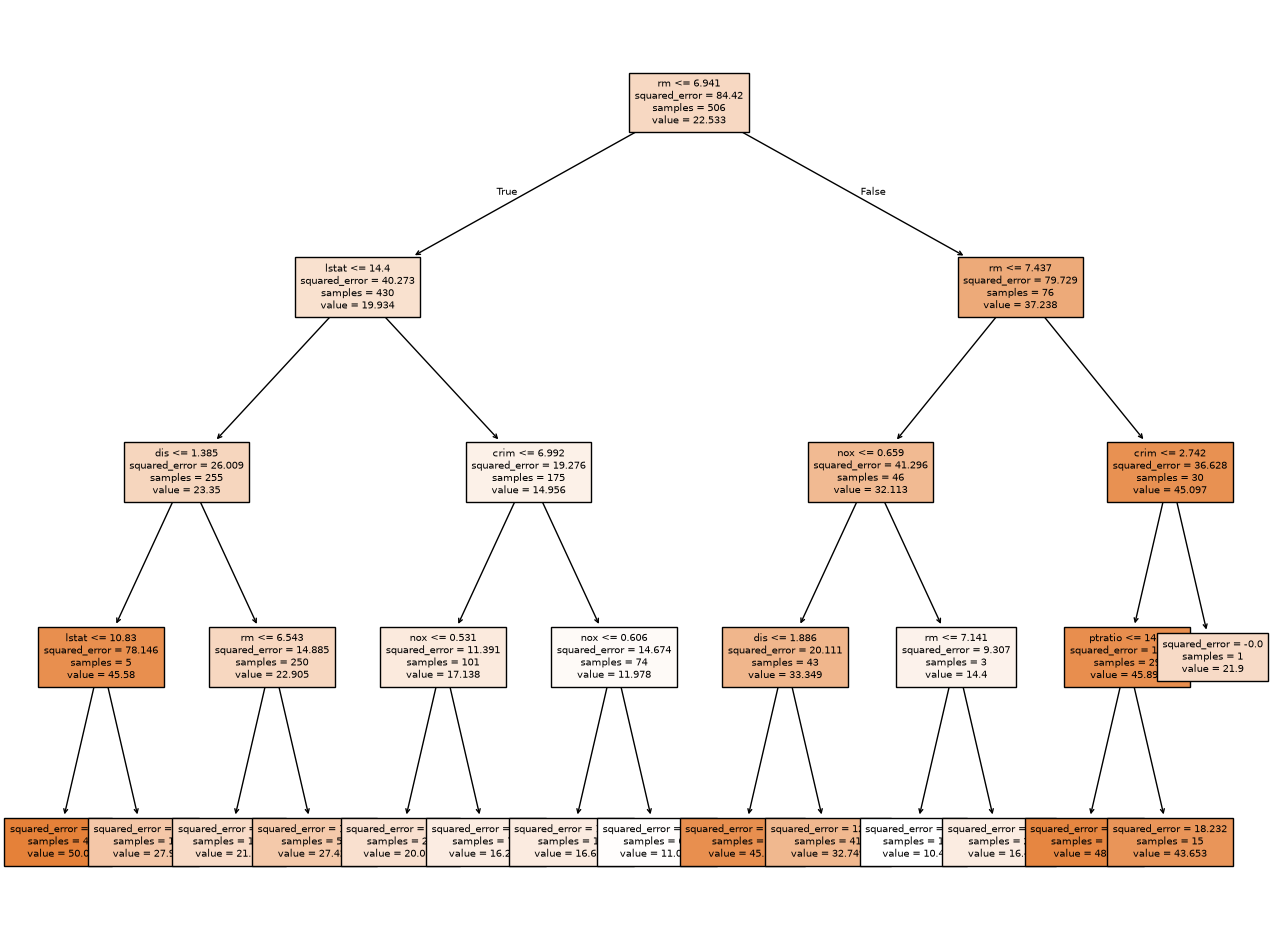

In [65]:
plt.figure(figsize = (16, 12))
tree.plot_tree(boston_tree, filled = True, feature_names = x.columns, fontsize = 7)
plt.show()